In [ ]:
from ml_homework.paths import RAW_DATA_DIR



**Завдання 1**: Завантажте дані `medical-charges.csv` в пандас датафрейм і виведіть перші 5 записів. Напишіть, як ви можете підійти до вирішення задачі прогнозування колонки `charges` на основі інших колонок виходячи з наявних на даний момент знань (без ML методів, чисто з використанням аналітики). Запишіть 3 або більше ідей, які приходять вам на думку нижче:

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [ ]:
medical_df = pd.read_csv(RAW_DATA_DIR / "medical/medical-charges.csv")

In [ ]:
medical_df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


1)Думаю варто проаналізувати як категоріальні та цифрові зміни можуть впливати на таргет і чи впливають ці змінні взгалі.

**Завдання 2**: Візуалізуйте розподіл медичних зборів (`charges`) у вигляді інтерактивної гістограми plotly з розбиттями за категоріями ознак
1. `sex`
2. `region`

Додайте маржинальний графік у вигляді бокс-плота вгорі по дикретним категоріям ознак.
Скористайтесь прикладом візуалізації з лекції.
Опишіть свої спостереження.

In [ ]:
fig = px.histogram(medical_df,
                   x='charges',
                   marginal='box',
                   color='sex',
                   color_discrete_sequence=['pink', 'grey'],
                   title='Distribution of medical charges by sex')
fig.update_layout(bargap=0.1)
fig.show()


Розподіл є зміщеним вправо: більшість людей мають відносно невеликі медичні збори, а невелика частина має дуже високі charges.

Для обох груп, male і female, більшість значень знаходиться приблизно в нижчому діапазоні, особливо до 15,000. Також в обох групах є викиди з високими значеннями charges, особливо після 30,000.

Box plot зверху показує, що медіани для male і female досить схожі. У групи male розкид значень виглядає трохи більшим, але візуально різниця між статями не дуже сильна.

Отже, за цим графіком можна сказати, що sex не виглядає як сильний окремий фактор впливу на medical charges.

In [ ]:
medical_df.groupby('region')['charges'].agg(['count', 'mean', 'median', 'min', 'max', 'std']).round(2)

,count,mean,median,min,max,std
region,,,,,,
northeast,324,13406.38,10057.65,1694.80,58571.07,11255.80
northwest,325,12417.58,8965.80,1621.34,60021.40,11072.28
southeast,364,14735.41,9294.13,1121.87,63770.43,13971.10
southwest,325,12346.94,8798.59,1241.56,52590.83,11557.18


In [ ]:
fig = px.histogram(medical_df,
                   x='charges',
                   marginal='box',
                   color='region',
                   color_discrete_sequence=['purple', 'grey', 'green', 'yellow'],
                   title='Distribution of medical charges by region')
fig.update_layout(bargap=0.1)
fig.show()

Розподіл у всіх регіонах є також правоскошеним: більшість людей мають відносно невеликі медичні збори, а невелика частина має дуже високі charges.

Медіани між регіонами не дуже сильно відрізняються, хоча northeast має трохи вищу медіану, а southwest — найнижчу.

За статистичними показниками найбільший розкид значень спостерігається у регіоні southeast, оскільки там найбільше стандартне відхилення і найвище максимальне значення charges.

Загалом region не виглядає як дуже сильний окремий фактор впливу на charges.

**Завдання 3**: Візуалізуйте з `plotly` розподіл кожного з настуних стовпців відносно того, чи є людина курцем (`smoker`)
- `region`
- `children`

та опишіть коротко свої спостереження.

In [ ]:
fig = px.histogram(
    medical_df,
    x='region',
    color='smoker',
    barmode='group',
    color_discrete_sequence=['pink', 'grey'],
    title='Distribution of region by smoker status',
)

fig.show()

Ми бачимо що в кожному регіоні більше людей, які не курять(або не зізнаються, що курять), як тих хто курить. В реегіоні southeast найбільше курящих у порівнянні з іншими регіонами, але різниця досить маленька,, тому за цим графіком не можна сказати, що region сильно впливає на те, чи є людина курцем.

In [ ]:
fig = px.histogram(
    medical_df,
    x='children',
    color='smoker',
    barmode='group',
    title='Distribution of smokers by number of children'
)

fig.show()

У даному графіку також, бачимо що не курців значно більше ніж курців в категріях з різною кількістю дітей. Можемо спостерігати, що найбільше не курців та курців(тобто всіх опитаних) у категорії 0 дітей. Але за даним графіком також не можна сказати, що кількість дітей сильно впливає на те, чи є людина курцем.

**Завдання 4**: Візуалізуйте звʼязок між стовпцем `charges` та `children` використовуючи графіки-скрипки (`px.violin`). Опишіть свої спостереження.

In [ ]:
fig = px.violin(
    medical_df,
    x='children',
    y='charges',
    box=True,
    title='charges vs children'
)

fig.show()

Можна помітити, що медіани charges для більшості категорій children знаходяться приблизно на схожому рівні.
У всіх категоріях є люди з відносно невеликими charges, але також помітно що є викиди. Найвищі charges зустрічаються не лише в одній конкретній групі, а в різних категоріях children.
Загалом, за цим графіком можна сказати, що children має слабкий або не дуже очевидний зв’язок із charges.

**Завдання 5.** Розглянемо модель для користувачів, які не є курцями (`no_smoker_df`):

$$charges = w \times age + b$$

Спробуйте 3 різні пари параметрів `w` та `b` аби вручну підігнати лінію під дані використовуючи наведені допоміжні функції `estimate_charges` та `try_parameters`. Опишіть спостереження.
Пари параметрів мають бути НЕ такі, як були наведені в лекції.

In [ ]:
non_smoker_df = medical_df[medical_df.smoker == 'no']

In [ ]:
def estimate_charges(age, w, b):
    return w * age + b

In [ ]:
def rmse(targets, predictions):
    return np.sqrt(np.mean(np.square(targets - predictions)))

In [ ]:
def try_parameters(df, w, b):
    ages = df.age
    target = df.charges

    predictions = estimate_charges(ages, w, b)

    plt.plot(ages, predictions, 'r', alpha=0.9)
    plt.scatter(ages, target, s=8, alpha=0.8)
    plt.xlabel('Age')
    plt.ylabel('Charges')
    plt.legend(['Estimate', 'Actual'])

    loss = rmse(target, predictions)
    print("RMSE Loss:", loss)

    return loss

RMSE Loss: 4705.696807404537


np.float64(4705.696807404537)

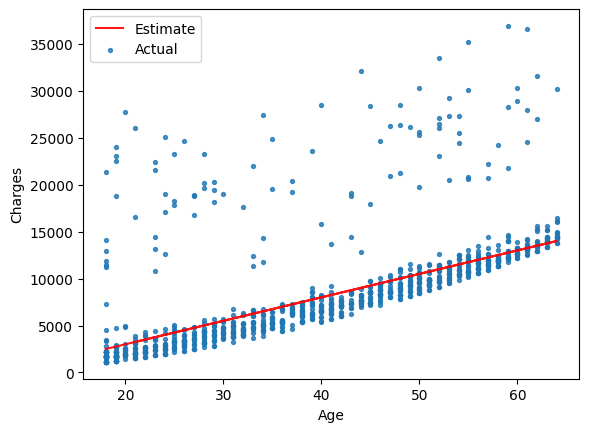

In [ ]:
try_parameters(non_smoker_df, 250, -2000)

RMSE Loss: 4686.746277005344


np.float64(4686.746277005344)

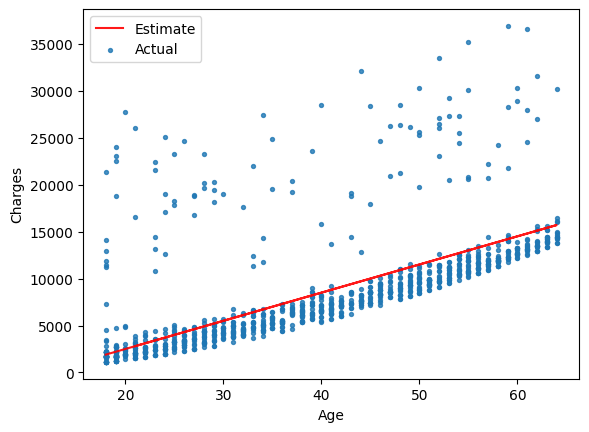

In [ ]:
try_parameters(non_smoker_df, 300, -3500)

RMSE Loss:  5080.98429455974


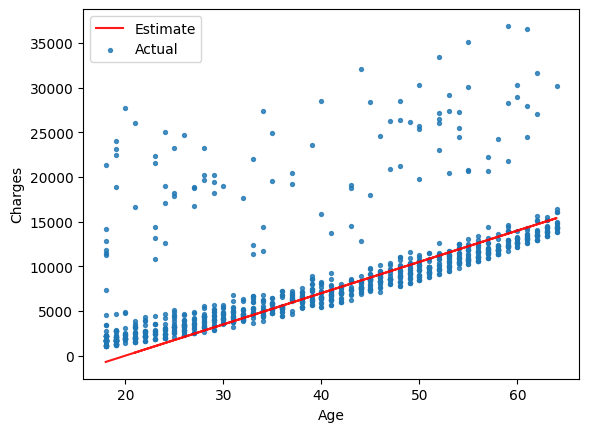

In [ ]:
try_parameters(non_smoker_df, 350, -7000)

На мою думку, найближчий результат спостереження try_parameters(non_smoker_df, 300, -3500), він виглядає найбільш точно(лінія найкраще проходить через основне скупчення точок) і RMSE Loss:  4686.74 не ідеальний, але найкращий з 3 спроб результат.

**Завдання 6**: Напишіть фукнцію для обчислення root mean squared error згідно з формулою цієї метрики точності моделі з використанням `numpy`.

Обчисліть RMSE для тих пар пареметрів, які Ви спробували в завданні 5.

Яке найнижче значення втрат ви зможете досягти? Чи можете ви придумати загальну стратегію для знаходження кращих значень $w$ та $b$ методом проб та помилок?

Якраз використовувала RMSE в попередньому завданні. Найнижче значення серед моїх спроб вийшло 4686.74. Можна взяти два масиви аднакової довжини для 𝑤  та 𝑏 в діапазоні, наприклад 𝑤 від 100 до 500 а 𝑏   від - 3300 до -3700. Пройтись по цим значенням циклом та визначити найкращий варіант.

In [ ]:
w_values_1 = np.array(range(100, 501))
b_values_1 = np.array(range(-3300 , -3701, -1))



In [ ]:
w_values_2 = np.array(range(-4900, 5501))
b_values_2 = np.array(range(1700, -8701, -1))

In [ ]:
def get_best_rmse(df, w_values, b_values):
    data = [
        (
            rmse(df.charges, estimate_charges(df.age, w, b)),
            w,
            b
        )
        for w, b in zip(w_values, b_values)
    ]

    best_rmse, best_w, best_b = min(data, key=lambda item: item[0])

    print('Best RMSE:', round(best_rmse, 2))
    print('Best w:', best_w)
    print('Best b:', best_b)

    return best_rmse, best_w, best_b

In [ ]:
get_best_rmse(non_smoker_df, w_values_1, b_values_1)

Best RMSE: 4686.51
Best w: 299
Best b: -3499


(np.float64(4686.51178754469), np.int64(299), np.int64(-3499))

In [ ]:
get_best_rmse(non_smoker_df, w_values_2, b_values_2)

Best RMSE: 4686.51
Best w: 299
Best b: -3499


(np.float64(4686.51178754469), np.int64(299), np.int64(-3499))

Виходить що найкращі значення -  Best w: 299
Best b: -3499, дуже близькі до тих, які я методом примірки підбирала на графіці вручну.

